In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython import display as ipythondisplay

/home/lucifer666/anaconda3/envs/py312/lib/python3.12/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [2]:
env = gym.make('Taxi-v4', render_mode='rgb_array')

state_size = env.observation_space.n
action_size = env.action_space.n
qtable = np.zeros((state_size, action_size))

In [3]:
# Learning Params
learning_rate = 0.9
discount_rate = 0.8
epsilon = 1
decay_rate = 0.005
num_episodes = 1000
max_steps = 99

In [4]:
state_size

np.int64(500)

In [5]:
action_size

np.int64(6)

In [6]:
qtable

array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]], shape=(500, 6))

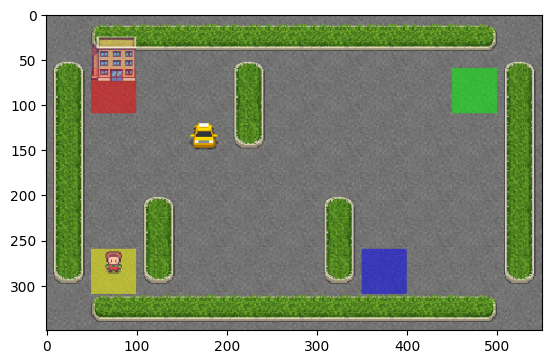

In [7]:
env.reset()
screen = env.render()
plt.imshow(screen)

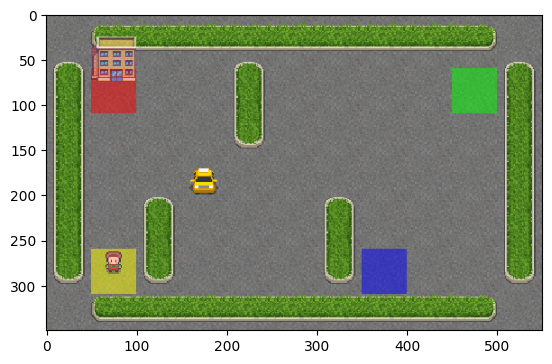

In [8]:
env.step(0)
# 0 -> move south, 1 -> move north, 2 -> move east
# 3 -> move west, 4 -> pickup passenger, 5 -> drop off passenger
screen = env.render()
plt.imshow(screen)

In [9]:
x = env.step(3)
print(x)

(208, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 1, 1, 0, 0, 0], dtype=int8)})


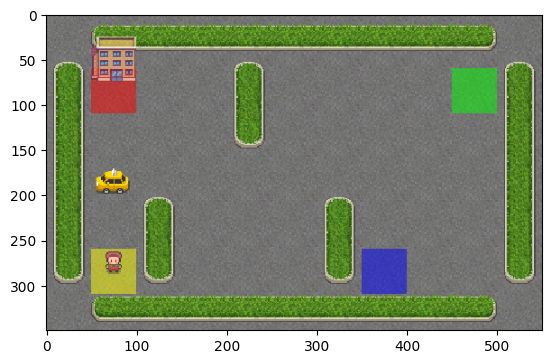

In [10]:
screen = env.render()
plt.imshow(screen)

## Training Agent

In [11]:
for episode in range(num_episodes):
    state, info = env.reset()
    done = False

    for s in range(max_steps):
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(qtable[state,:])
        
        new_state, reward, done, *info = env.step(action=action)
        # Q formula
        qtable[state, action] = qtable[state, action] + learning_rate * (reward + discount_rate * np.max(qtable[new_state,:]) - qtable[state, action])

        state = new_state

        if done == True:
            break

    epsilon = np.exp(-decay_rate * episode)

    print(f'Training complete over {num_episodes} episodes')


Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
Training complete over 1000 episodes
T

In [12]:
qtable

array([[  0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ],
       [ -2.86649163,  -2.31586724,  -4.47180972,  -2.31767303,
         -1.6445568 , -11.51497692],
       [  0.03142154,   1.52391163,   0.22019345,  -2.78901432,
          3.192     ,  -7.74388117],
       ...,
       [ -3.22321662,   5.2366558 ,  -3.18699174,  -2.88389616,
         -9.99      , -11.759364  ],
       [ -3.19570256,  -1.27783897,  -3.33623058,  -3.23612353,
        -11.31573082, -12.13746086],
       [ -1.7118    ,  -1.78308   ,  -1.7118    ,  15.        ,
          0.72878556,  -9.        ]], shape=(500, 6))

In [13]:
state, info = env.reset()
done = False
rewards = 0

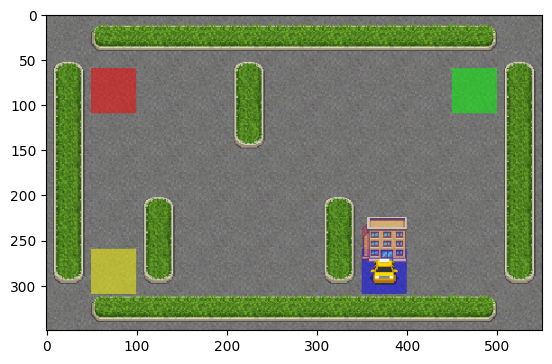

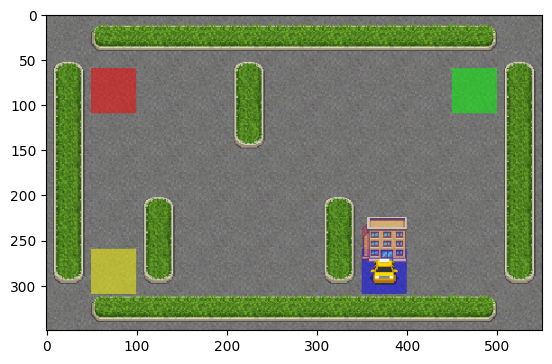

In [14]:
for s in range(max_steps):
    print('Trained Agent')
    print(f'step {s+1}')
    screen = env.render()
    plt.imshow(screen)

    action = np.argmax(qtable[state,:])
    new_state, reward, done, *info = env.step(action=action)
    rewards += reward
    print(f'Agent Score: {rewards}')
    state = new_state

    ipythondisplay.clear_output(wait=True)
    ipythondisplay.display(plt.gcf())

    if done == True:
        break

env.close()